In [1]:
import random
random.seed(42)

# Modell 222 LSTM with Keras

### Was kann dieses Modell?

### Daten: alle Rennen
### Modelle: LSTM, aber besser sequenziert
### Training: sequentiell
### Vorhersage: Probs für alle Fahrer
### Problem: ???

## Imports

In [2]:
import fastf1
from fastf1 import plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

# sklearn related imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import brier_score_loss
from sklearn.utils.class_weight import compute_sample_weight



project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(project_root)
from utils.Feature_Engineer import FeatureEngineer
from utils.Metrics import Metrics
from utils.Models import Models
from utils.experiment_db import init_db
init_db()


pd.set_option('display.width', None)         # passt die Ausgabe-Breite an
pd.set_option('display.max_columns', None)   # zeigt alle Spalten
pd.set_option('display.max_rows', None)      # zeigt alle Reihen

%load_ext autoreload
%autoreload 2

## Rennen definieren

In [3]:
schedule = fastf1.get_event_schedule(2024, include_testing=False)
print(schedule["EventName"].tolist())

req         WARNING 	DEFAULT CACHE ENABLED! (2.5 GB) /Users/lukaskoch/Library/Caches/fastf1


['Bahrain Grand Prix', 'Saudi Arabian Grand Prix', 'Australian Grand Prix', 'Japanese Grand Prix', 'Chinese Grand Prix', 'Miami Grand Prix', 'Emilia Romagna Grand Prix', 'Monaco Grand Prix', 'Canadian Grand Prix', 'Spanish Grand Prix', 'Austrian Grand Prix', 'British Grand Prix', 'Hungarian Grand Prix', 'Belgian Grand Prix', 'Dutch Grand Prix', 'Italian Grand Prix', 'Azerbaijan Grand Prix', 'Singapore Grand Prix', 'United States Grand Prix', 'Mexico City Grand Prix', 'São Paulo Grand Prix', 'Las Vegas Grand Prix', 'Qatar Grand Prix', 'Abu Dhabi Grand Prix']


In [4]:
YEAR = 2024
GRAND_PRIX = schedule['EventName'].to_list()
SESSION_TYPE = "R"

In [5]:
all_laps = []
for gp in GRAND_PRIX:
    try:
        session = fastf1.get_session(YEAR, gp, SESSION_TYPE)
        session.load(weather=True, laps=True, telemetry=True)
        laps = session.laps.copy()
        weather = session.weather_data.copy()
        
        laps = laps.sort_values("Time")
        weather = weather.sort_values("Time")

        merged = pd.merge_asof(
                laps,
                weather,
                on="Time",
                direction="backward"
            )
        
        merged['GP'] = gp
        merged['Year'] = YEAR
        
        all_laps.append(merged)
        print(f"✔ Loaded {gp}")
        
    except Exception as e:
        print(f"Error loading {gp}: {e}")
        
data = pd.concat(all_laps, ignore_index=True)

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.7.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '55', '16', '63', '4', '44', '81', '14', '18', '24', '20', '3', '22', '23', '27', '31', '10', '77', '2']
core           INFO 	Loading data for Saudi Arabian Grand Prix

✔ Loaded Bahrain Grand Prix


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '16', '81', '14', '63', '38', '4', '44', '27', '23', '20', '31', '2', '22', '3', '77', '24', '18', '10']
core           INFO 	Loading data for Australian Grand Prix - Race [v3.7.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


✔ Loaded Saudi Arabian Grand Prix


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 19 drivers: ['55', '16', '4', '81', '11', '18', '22', '14', '27', '20', '23', '3', '10', '77', '24', '31', '63', '44', '1']
core           INFO 	Loading data for Japanese Grand Prix - Race [v3.7.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


✔ Loaded Australian Grand Prix


... (38 outputs left out)

core        WARNING 	Fixed incorrect tyre stint information for driver '43'
core        WARNING 	Fixed incorrect tyre stint information for driver '31'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '16', '81', '63', '10', '55', '14', '24', '20', '4', '77', '44', '22', '30', '23', '27', '11', '18', '43', '31']
core           INFO 	Loading data for Abu Dhabi Grand Prix - Race [v3.7.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req         

✔ Loaded Qatar Grand Prix


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '55', '16', '44', '63', '1', '10', '27', '14', '81', '23', '22', '24', '18', '61', '20', '30', '77', '43', '11']


✔ Loaded Abu Dhabi Grand Prix


In [6]:
fe = FeatureEngineer()
merged = fe.create_features(data)

In [7]:
features = fe.choose_features(merged)
features

['gapAheadSeconds',
 's1_delta',
 's2_delta',
 's3_delta',
 'lap_pace_delta',
 'is_raining',
 'position_change',
 'compound_HARD',
 'compound_INTERMEDIATE',
 'compound_MEDIUM',
 'compound_SOFT',
 'compound_WET',
 'status_1',
 'status_12',
 'status_124',
 'status_125',
 'status_1254',
 'status_126',
 'status_1264',
 'status_1267',
 'status_14',
 'status_16',
 'status_167',
 'status_21',
 'status_24',
 'status_26',
 'status_267',
 'status_2671',
 'status_4',
 'status_41',
 'status_412',
 'status_45',
 'status_51',
 'status_6',
 'status_64',
 'status_671',
 'status_71']

In [8]:
race_order = (
    merged.groupby(["GP", "Year"])["LapStartDate"]
      .min()
      .sort_values()
      .reset_index()[["GP", "Year"]]
)

race_order

,GP,Year
0,Bahrain Grand Prix,2024
1,Saudi Arabian Grand Prix,2024
2,Australian Grand Prix,2024
3,Japanese Grand Prix,2024
4,Chinese Grand Prix,2024
5,Miami Grand Prix,2024
6,Emilia Romagna Grand Prix,2024
7,Monaco Grand Prix,2024
8,Canadian Grand Prix,2024
9,Spanish Grand Prix,2024


In [9]:
target_col = "pit_in_next_lap"

## Sequenzen pro Fahrer und Rennen

In [10]:
group_cols = ["GP", "Driver"]

X_sequences = []
y_sequences = []

for (gp, driver), df_grp in merged.groupby(group_cols):

    df_grp = df_grp.sort_values("LapNumber")

    X_seq = df_grp[features].astype(float).fillna(0).values
    y_seq = df_grp[target_col].astype(int).values

    if len(X_seq) < 2:
        continue

    X_sequences.append(X_seq)
    y_sequences.append(y_seq)

print(f"Extrahierte Sequenzen: {len(X_sequences)}")

Extrahierte Sequenzen: 464


## Padding für LSTM

In [11]:
import tensorflow
from tensorflow.keras.preprocessing.sequence import pad_sequences # type: ignore

X_padded = pad_sequences(X_sequences, padding="post", dtype="float32")
y_padded = pad_sequences(y_sequences, padding="post", dtype="float32")

print("X_padded Shape:", X_padded.shape)
print("y_padded Shape:", y_padded.shape)

X_padded Shape: (464, 78, 37)
y_padded Shape: (464, 78)


## Train-Test-Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_padded, y_padded, test_size=0.2, shuffle=True
)

num_features = X_train.shape[-1]

y_train = np.expand_dims(y_train, axis=-1)
y_test = np.expand_dims(y_test, axis=-1)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

y_train shape: (371, 78, 1)
y_test shape: (93, 78, 1)


## LSTM Modell

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential # type: ignore
from tensorflow.keras.layers import LSTM, Dense, Masking # type: ignore
from tensorflow.keras.optimizers import Adam # type: ignore
from tensorflow.keras.metrics import AUC, Precision, Recall # type: ignore
from tensorflow.keras.layers import Dropout # type: ignore
from tensorflow.keras.layers import BatchNormalization # type: ignore


In [14]:
# model = Sequential([
#     Masking(mask_value=0.0, input_shape=(None, num_features)),
#     LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
#     Dense(32, activation="relu"),
#     Dense(1, activation="sigmoid")
    
# ])

model = Sequential([
    LSTM(64, return_sequences=True),
    Dense(1, activation="sigmoid")
    
])

model.compile(
    optimizer=Adam(1e-3),
    loss='binary_crossentropy',
    metrics=[
        AUC(name="auc"), 
        Precision(name="precision"), 
        Recall(name="recall")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=100,
    validation_split=0.1
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - auc: 0.4552 - loss: 0.4823 - precision: 0.0252 - recall: 0.0844 - val_auc: 0.4257 - val_loss: 0.2883 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.4718 - loss: 0.1971 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_auc: 0.5181 - val_loss: 0.1357 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.5289 - loss: 0.1301 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_auc: 0.5388 - val_loss: 0.1327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.5493 - loss: 0.1262 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_auc: 0.5423 - val_loss: 0.1281 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - auc: 0.5671 - loss: 0.1217 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_auc: 0.5402 

In [16]:
y_pred_prob = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


In [17]:
# Unpack padded sequences into flat 1D arrays
y_true_flat = []
y_pred_flat = []

for yt_seq, yp_seq in zip(y_test, y_pred_prob):
    # yt_seq: (timesteps, 1)
    # yp_seq: (timesteps, 1)

    # Mask: nur gültige Timesteps
    mask = (yt_seq >= 0)  # oder >-1, falls Padding=0 erlaubt ist
    yt_valid = yt_seq[mask].reshape(-1)
    yp_valid = yp_seq[mask].reshape(-1)

    y_true_flat.append(yt_valid)
    y_pred_flat.append(yp_valid)

y_true_flat = np.concatenate(y_true_flat)
y_pred_flat = np.concatenate(y_pred_flat)

print("Flattened shapes:", y_true_flat.shape, y_pred_flat.shape)

Flattened shapes: (7254,) (7254,)


In [18]:
from utils.experiment_db import log_or_update_metrics

metrics = Metrics.calculate_metrics(f"approach_222_LSTM", y_true_flat, y_pred_flat)
Metrics.print_metrics(metrics)
    
    
log_or_update_metrics(
    model_name=f"approach_222_{LSTM}",
    metrics={
        **metrics
    }
)

   ✔ Brier-Score:              0.0211 -> optimal 0.0
   ✔ Log-Loss:                 0.0894 -> optimal 0.0
   ✔ ROC-AUC:                  0.8574 -> optimal 1.0
   ✔ PR-AUC:                   0.1768 -> optimal 1.0


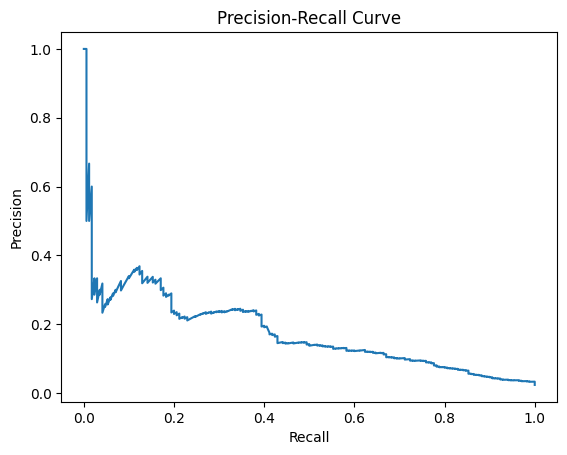

In [19]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_true_flat, y_pred_flat)

import matplotlib.pyplot as plt
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()


In [20]:
from sklearn.metrics import precision_recall_curve
import numpy as np

prec, rec, thr = precision_recall_curve(y_true_flat, y_pred_flat)

# F1 Score
f1 = 2 * prec * rec / (prec + rec + 1e-9)

best = np.argmax(f1)
print("Best Threshold:", thr[best])
print("Precision:", prec[best])
print("Recall:", rec[best])
print("F1:", f1[best])



Best Threshold: 0.15154475
Precision: 0.23985239852398524
Recall: 0.38235294117647056
F1: 0.29478458002509245
